# 2023 — Speculative Decoding: Faster Generation, Same Distribution

**Papers:** Yaniv Leviathan, Matan Kalman & Yossi Matias, *"Fast Inference from Transformers via Speculative Decoding"* (2022/ICML 2023); Charlie Chen et al., *"Accelerating Large Language Model Decoding with Speculative Sampling"* (DeepMind, 2023). Successors: Medusa (2024), EAGLE (2024), and **multi-token-prediction heads** used as drafters (DeepSeek-V3, Qwen3.5; notebook 47).

Generating with a big LLM is slow because it is **one token per forward pass**, and each pass is limited by memory bandwidth, not arithmetic. Checking $k$ tokens in one pass costs about the same as generating one.

**Speculative sampling:**
1. a small, fast **draft** model $q$ proposes $\gamma$ tokens
2. the big **target** model $p$ scores all of them in **one** forward pass
3. accept each draft token $x$ with probability $\min\!\big(1, \frac{p(x)}{q(x)}\big)$; at the first rejection, resample from the residual $\operatorname{norm}(\max(0, p - q))$ and stop
4. if all $\gamma$ are accepted, sample one bonus token from $p$

This is **mathematically exact**: the output has precisely the target model's distribution, not an approximation. The speed-up depends on how often the draft agrees with the target.

In [1]:
import os, math, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

def get_device():
    """CUDA > Apple MPS > CPU. Force one with the env var NN_DEVICE=cpu|cuda|mps."""
    forced = os.environ.get("NN_DEVICE")
    if forced:
        return torch.device(forced)
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

device = get_device()
torch.set_flush_denormal(True)   # tiny "denormal" floats are extremely slow on CPUs; treat them as 0
seed_everything(0)
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0 | device: mps


In [2]:
# A procedurally generated corpus (~290K characters) with a real held-out split.
_rng = random.Random(0)
_subjects = ["the model", "a small network", "the optimizer", "each layer", "the attention head", "the router", "a student", "the teacher"]
_verbs = ["learns", "predicts", "updates", "compresses", "routes", "remembers", "forgets", "copies"]
_objects = ["the next token", "a hidden state", "the gradient", "its weights", "a long context", "the key and value", "every expert", "the loss"]
_advs = ["quickly", "slowly", "carefully", "in parallel", "step by step", "without labels", "at scale", "once again"]
def _sentence():
    s = f"{_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)} {_rng.choice(_advs)}"
    if _rng.random() < 0.4: s += f" because {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    if _rng.random() < 0.2: s += f", then {_rng.choice(_subjects)} {_rng.choice(_verbs)} {_rng.choice(_objects)}"
    return s[0].upper() + s[1:] + ". "
text = "".join(_sentence() for _ in range(4000))
chars = sorted(set(text)); V = len(chars); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text], device=device)
split = int(0.9 * len(data)); train_data, val_data = data[:split], data[split:]
encode = lambda s: [stoi[c] for c in s]; decode = lambda ids: "".join(chars[i] for i in ids)
print(f"{len(text):,} characters, vocab {V}")

290,321 characters, vocab 31


In [3]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.proj, self.h = nn.Linear(d, 3 * d), nn.Linear(d, d), heads
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def forward(self, x):
        B, T, D = x.shape
        q, k, v = self.qkv(self.ln1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
        x = x + self.proj(F.scaled_dot_product_attention(q, k, v, is_causal=True).transpose(1, 2).reshape(B, T, D))
        return x + self.mlp(self.ln2(x))

class GPT(nn.Module):
    """A small GPT-2-style character model (pre-norm blocks, learned positions)."""
    def __init__(self, V, d=128, n_layers=4, heads=4, ctx=128):
        super().__init__()
        self.ctx = ctx
        self.tok, self.pos = nn.Embedding(V, d), nn.Embedding(ctx, d)
        self.blocks = nn.ModuleList([Block(d, heads) for _ in range(n_layers)])
        self.ln, self.head = nn.LayerNorm(d), nn.Linear(d, V, bias=False)
    def forward(self, idx):
        x = self.tok(idx) + self.pos(torch.arange(idx.shape[1], device=idx.device))
        for b in self.blocks: x = b(x)
        return self.head(self.ln(x))

def train_gpt(model, train_data, steps=800, B=32, lr=2e-3):
    model = model.to(train_data.device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, lr, total_steps=steps, pct_start=0.1)
    for s in range(steps):
        ix = torch.randint(0, len(train_data) - model.ctx - 1, (B,), device=train_data.device)
        x = torch.stack([train_data[i:i + model.ctx] for i in ix]); y = torch.stack([train_data[i + 1:i + model.ctx + 1] for i in ix])
        loss = F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1))
        opt.zero_grad(); loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    return model.eval()

@torch.no_grad()
def eval_loss(model, data, n=20, B=32):
    g = torch.Generator(device="cpu").manual_seed(123); losses = []
    for _ in range(n):
        ix = torch.randint(0, len(data) - model.ctx - 1, (B,), generator=g).to(data.device)
        x = torch.stack([data[i:i + model.ctx] for i in ix]); y = torch.stack([data[i + 1:i + model.ctx + 1] for i in ix])
        losses.append(F.cross_entropy(model(x).reshape(-1, model.head.out_features), y.reshape(-1)).item())
    return float(np.mean(losses))

seed_everything(0); t0 = time.time()
target = train_gpt(GPT(V, d=192, n_layers=6, heads=6), train_data, steps=800)
seed_everything(0)
draft = train_gpt(GPT(V, d=48, n_layers=1, heads=2), train_data, steps=800)
n_params = lambda m: sum(p.numel() for p in m.parameters())
print(f"target: {n_params(target) / 1e6:.2f}M params, val loss {eval_loss(target, val_data):.3f}")
print(f"draft : {n_params(draft) / 1e6:.3f}M params ({n_params(target) / n_params(draft):.0f}x smaller), val loss {eval_loss(draft, val_data):.3f}")
print(f"(trained in {time.time() - t0:.0f}s)")

target: 2.71M params, val loss 0.212


draft : 0.037M params (72x smaller), val loss 0.652
(trained in 124s)


In [4]:
@torch.no_grad()
def probs(model, seq, temperature):
    return F.softmax(model(seq[:, -model.ctx:])[0] / temperature, -1)          # next-token distributions at every position

@torch.no_grad()
def generate_naive(prompt, n, temperature=1.0):
    seq = torch.tensor([encode(prompt)], device=device); calls = 0
    while seq.shape[1] < len(prompt) + n:
        p = probs(target, seq, temperature)[-1]; calls += 1
        seq = torch.cat([seq, torch.multinomial(p, 1)[None]], 1)
    return seq[0, len(prompt):len(prompt) + n].tolist(), calls

@torch.no_grad()
def generate_speculative(prompt, n, gamma=4, temperature=1.0):
    seq = torch.tensor([encode(prompt)], device=device); target_calls, accepted = 0, 0
    while seq.shape[1] < len(prompt) + n:
        # 1) draft proposes gamma tokens autoregressively (cheap)
        draft_seq, q_dists = seq, []
        for _ in range(gamma):
            q = probs(draft, draft_seq, temperature)[-1]; q_dists.append(q)
            draft_seq = torch.cat([draft_seq, torch.multinomial(q, 1)[None]], 1)
        proposal = draft_seq[0, seq.shape[1]:]
        # 2) target scores the prefix + all gamma proposals in ONE forward pass
        p_all = probs(target, draft_seq, temperature)[-(gamma + 1):]             # gamma + 1 distributions: after the prefix and after each proposal
        target_calls += 1
        # 3) accept / reject left to right
        new = []
        for i, x in enumerate(proposal.tolist()):
            p, q = p_all[i], q_dists[i]
            if torch.rand(()) < torch.clamp(p[x] / q[x], max=1.0):
                new.append(x); accepted += 1
            else:
                residual = torch.clamp(p - q, min=0); new.append(torch.multinomial(residual / residual.sum(), 1).item())
                break
        else:
            new.append(torch.multinomial(p_all[gamma], 1).item())                 # 4) all accepted: free bonus token
        seq = torch.cat([seq, torch.tensor([new], device=device)], 1)
    return seq[0, len(prompt):len(prompt) + n].tolist(), target_calls, accepted

prompt = "The model "
out, calls, acc = generate_speculative(prompt, 300, gamma=4, temperature=0.8)
print(prompt + decode(out))
print(f"\n300 tokens with {calls} target forward passes ({300 / calls:.2f} tokens per target call; naive decoding needs 300)")

The model predicts every expert step by step. A small network predicts the loss at scale, then a student learns the key and value. Each layer remembers its weights carefully because a student learns the gradient. A student forgets the key and value at scale. Each layer remembers the gradient carefully because

300 tokens with 169 target forward passes (1.78 tokens per target call; naive decoding needs 300)


## Exactness check
Compare the distribution of the first generated token under both methods with the target model's exact probabilities. Both should match within sampling noise. (The draft is noticeably worse than the target, so a biased method would show up.)

In [5]:
prompt = "The attention head "
exact = probs(target, torch.tensor([encode(prompt)], device=device), 1.0)[-1].cpu()
N = 3000
naive_counts, spec_counts = torch.zeros(V), torch.zeros(V)
for _ in range(N):
    naive_counts[generate_naive(prompt, 1)[0][0]] += 1
    spec_counts[generate_speculative(prompt, 1, gamma=3)[0][0]] += 1
draft_exact = probs(draft, torch.tensor([encode(prompt)], device=device), 1.0)[-1].cpu()
tv = lambda a, b: 0.5 * (a - b).abs().sum().item()
print(f"total-variation distance from the exact target distribution ({N} samples each):")
print(f"  naive sampling       {tv(naive_counts / N, exact):.3f}")
print(f"  speculative sampling {tv(spec_counts / N, exact):.3f}")
print(f"  (the draft model's own distribution is {tv(draft_exact, exact):.3f} away, so a method that leaked draft bias would show)")

total-variation distance from the exact target distribution (3000 samples each):
  naive sampling       0.014
  speculative sampling 0.017
  (the draft model's own distribution is 0.472 away, so a method that leaked draft bias would show)


## Speed-up vs. draft length γ
Expected tokens per target call is $\frac{1-\alpha^{\gamma+1}}{1-\alpha}$, where $\alpha$ is the per-token acceptance rate. Longer drafts help only while the draft keeps agreeing with the target.

gamma=1: 1.40 tokens per target call | draft acceptance rate 0.40


gamma=2: 1.57 tokens per target call | draft acceptance rate 0.28


gamma=4: 1.77 tokens per target call | draft acceptance rate 0.19


gamma=6: 1.74 tokens per target call | draft acceptance rate 0.12


gamma=8: 1.77 tokens per target call | draft acceptance rate 0.10


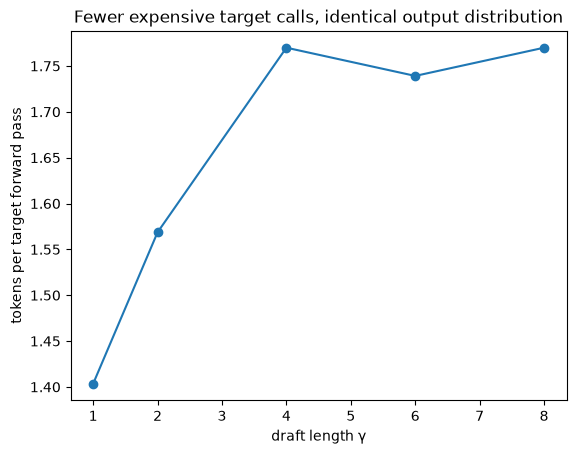

In [6]:
rows = []
for gamma in [1, 2, 4, 6, 8]:
    _, calls, acc = generate_speculative("Each layer ", 400, gamma=gamma, temperature=0.8)
    rows.append((gamma, 400 / calls, acc / (calls * gamma)))
    print(f"gamma={gamma}: {400 / calls:.2f} tokens per target call | draft acceptance rate {acc / (calls * gamma):.2f}")
plt.plot([r[0] for r in rows], [r[1] for r in rows], marker="o"); plt.xlabel("draft length γ"); plt.ylabel("tokens per target forward pass")
plt.title("Fewer expensive target calls, identical output distribution"); plt.show()